In [11]:
import matplotlib.pyplot as plt
from picamera2 import Picamera2
from IPython.display import display, clear_output
import time

# Initialize two cameras (right = 0, left = 1)
picam_right = Picamera2(0)  # Right camera (ID 0)
picam_left = Picamera2(1)   # Left camera (ID 1)

# Define optimized video configurations for both cameras
config_right = picam_right.create_video_configuration(
    main={"size": (640, 480), "format": "YUV420"},
    display=None,
    buffer_count=6,
    controls={"FrameRate": 30}
)

config_left = picam_left.create_video_configuration(
    main={"size": (640, 480), "format": "YUV420"},
    display=None,
    buffer_count=6,
    controls={"FrameRate": 30}
)

# Apply configurations and start both cameras
picam_right.configure(config_right)
picam_left.configure(config_left)

picam_right.start()
picam_left.start()
frame_times = []

try:
    # Setup Matplotlib figure
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))  # Two side-by-side plots

    while True:
        start_time = time.perf_counter()
        # Capture frames from both cameras (YUV420 format)
        frame_right = picam_right.capture_array("main")
        frame_left = picam_left.capture_array("main")

        # Extract only the Y (grayscale) channel
        h, w = 480, 640  # Image dimensions (same as "size" in config)
        frame_right_gray = frame_right[:h, :]  # Take only Y channel (top part)
        frame_left_gray = frame_left[:h, :]    # Take only Y channel (top part)

        # Clear previous output and update both images
        clear_output(wait=True)
        axes[0].imshow(frame_right_gray, cmap="gray")
        axes[0].set_title("Right Camera")
        axes[0].axis("off")

        axes[1].imshow(frame_left_gray, cmap="gray")
        axes[1].set_title("Left Camera")
        axes[1].axis("off")

        display(fig)
        frame_time = time.perf_counter() - start_time
        frame_times.append(frame_time)
        print(f"Frame time: {frame_time:.2f} seconds")
        if len(frame_times) > 10:
            frame_times.pop(0)
        avg_frame_time = sum(frame_times) / len(frame_times)
        print(f"Average frame time: {avg_frame_time:.2f} seconds")

except KeyboardInterrupt:
    print("Streaming stopped.")

finally:
    # Stop cameras properly
    picam_right.close()
    picam_left.close()

Streaming stopped.


In [3]:
# Release the webcam
picam_right.close()
picam_left.close()

[0:02:16.761002154] [1376]  INFO Camera camera_manager.cpp:327 libcamera v0.4.0+53-29156679
[0:02:16.771118983] [1750]  INFO RPI pisp.cpp:720 libpisp version v1.1.0 e7974a156008 27-01-2025 (21:50:51)
[0:02:16.780589835] [1750]  INFO RPI pisp.cpp:1179 Registered camera /base/axi/pcie@120000/rp1/i2c@88000/imx219@10 to CFE device /dev/media0 and ISP device /dev/media2 using PiSP variant BCM2712_C0
[0:02:16.780646776] [1750]  INFO RPI pisp.cpp:720 libpisp version v1.1.0 e7974a156008 27-01-2025 (21:50:51)
[0:02:16.789687414] [1750]  INFO RPI pisp.cpp:1179 Registered camera /base/axi/pcie@120000/rp1/i2c@80000/imx219@10 to CFE device /dev/media3 and ISP device /dev/media4 using PiSP variant BCM2712_C0
[0:02:16.794915966] [1376]  INFO Camera camera.cpp:1202 configuring streams: (0) 640x480-YUV420 (1) 640x480-BGGR_PISP_COMP1
[0:02:16.795027181] [1750]  INFO RPI pisp.cpp:1484 Sensor: /base/axi/pcie@120000/rp1/i2c@88000/imx219@10 - Selected sensor format: 640x480-SBGGR10_1X10 - Selected CFE forma

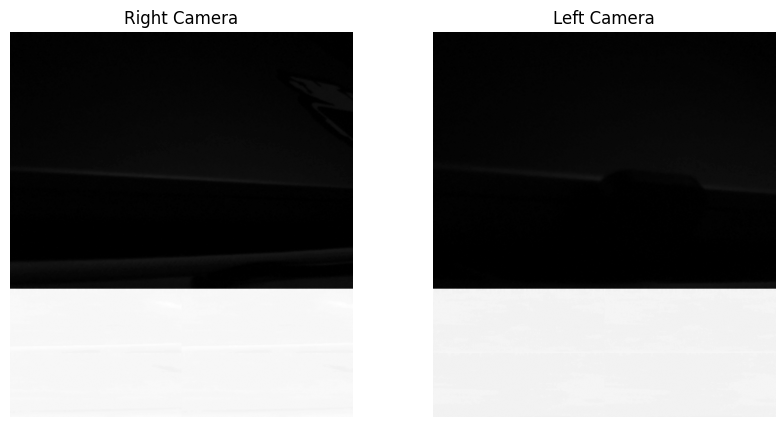

Streaming stopped.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from picamera2 import Picamera2

# Initialize two cameras (right = 0, left = 1)
picam_right = Picamera2(0)  # Right camera (ID 0)
picam_left = Picamera2(1)   # Left camera (ID 1)

# Define optimized video configurations for both cameras
config_right = picam_right.create_video_configuration(
    main={"size": (640, 480), "format": "YUV420"},
    display=None,
    buffer_count=6,  # Increased buffer count for smoother streaming
    controls={"FrameRate": 30, "ExposureTime": 5000, "AnalogueGain": 1.2}
)

config_left = picam_left.create_video_configuration(
    main={"size": (640, 480), "format": "YUV420"},
    display=None,
    buffer_count=6,
    controls={"FrameRate": 30, "ExposureTime": 5000, "AnalogueGain": 1.2}
)

# Apply configurations and start both cameras
picam_right.configure(config_right)
picam_left.configure(config_left)

picam_right.start()
picam_left.start()

# Set up Matplotlib figure
plt.ion()  # Interactive mode ON
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Create placeholders for images
frame_right = picam_right.capture_array("main")
frame_left = picam_left.capture_array("main")

# Extract only the Y (grayscale) channel (first height rows)
h, w = frame_right.shape[0], frame_right.shape[1]
frame_right_gray = frame_right[:h, :]
frame_left_gray = frame_left[:h, :]

# Initialize image plots with first frame
img_right = axes[0].imshow(frame_right_gray, cmap="gray", animated=True)
axes[0].set_title("Right Camera")
axes[0].axis("off")

img_left = axes[1].imshow(frame_left_gray, cmap="gray", animated=True)
axes[1].set_title("Left Camera")
axes[1].axis("off")

plt.show()

try:
    while True:
        start_time = time.perf_counter()
        # Capture new frames
        frame_right = picam_right.capture_array("main")
        frame_left = picam_left.capture_array("main")

        # Extract grayscale (Y channel)
        frame_right_gray = frame_right[:h, :]
        frame_left_gray = frame_left[:h, :]

        # Update the displayed images
        img_right.set_data(frame_right_gray)
        img_left.set_data(frame_left_gray)

        # Redraw without clearing the output
        fig.canvas.draw_idle()
        plt.pause(0.03)
        frame_time = time.perf_counter() - start_time
        # print(f"Frame time: {frame_time:.2f} seconds")

except KeyboardInterrupt:
    print("Streaming stopped.")

finally:
    # Stop cameras properly
    picam_right.close()
    picam_left.close()
    plt.ioff()  # Turn off interactive mode

In [1]:
import ipywidgets as widgets
from IPython.display import display
import numpy as np
from picamera2 import Picamera2
import time

# Initialize two cameras (right = 0, left = 1)
picam_right = Picamera2(0)  # Right camera (ID 0)
picam_left = Picamera2(1)   # Left camera (ID 1)

# Define optimized video configurations for both cameras
config_right = picam_right.create_video_configuration(
    main={"size": (640, 480), "format": "YUV420"},
    display=None,
    buffer_count=6,
    controls={"FrameRate": 30, "ExposureTime": 5000, "AnalogueGain": 1.2}
)

config_left = picam_left.create_video_configuration(
    main={"size": (640, 480), "format": "YUV420"},
    display=None,
    buffer_count=6,
    controls={"FrameRate": 30, "ExposureTime": 5000, "AnalogueGain": 1.2}
)

# Apply configurations and start both cameras
picam_right.configure(config_right)
picam_left.configure(config_left)

picam_right.start()
picam_left.start()

# Create image widgets for both cameras
image_widget_right = widgets.Image(format='jpeg', width=320, height=240)
image_widget_left = widgets.Image(format='jpeg', width=320, height=240)

# Display widgets side by side
display(widgets.HBox([
    widgets.VBox([widgets.Label('Right Camera'), image_widget_right]),
    widgets.VBox([widgets.Label('Left Camera'), image_widget_left])
]))

try:
    while True:
        start_time = time.perf_counter()
        
        # Capture frames
        frame_right = picam_right.capture_array("main")
        frame_left = picam_left.capture_array("main")
        
        # Extract grayscale (Y channel)
        frame_right_gray = frame_right[:480, :]
        frame_left_gray = frame_left[:480, :]

        # Do histogram equalization
        frame_right_gray = cv2.equalizeHist(frame_right_gray)
        frame_left_gray = cv2.equalizeHist(frame_left_gray)
        
        # Convert to jpeg bytes
        import cv2
        _, right_buffer = cv2.imencode('.jpg', frame_right_gray)
        _, left_buffer = cv2.imencode('.jpg', frame_left_gray)
        
        # Update widgets
        image_widget_right.value = right_buffer.tobytes()
        image_widget_left.value = left_buffer.tobytes()
        
        frame_time = time.perf_counter() - start_time
        print(f"\rFrame time: {frame_time:.3f} seconds", end="")
        
except KeyboardInterrupt:
    print("\nStreaming stopped.")
    
finally:
    # Stop cameras properly
    picam_right.close()
    picam_left.close()

[0:01:52.381071690] [1376]  INFO Camera camera_manager.cpp:327 libcamera v0.4.0+53-29156679
[0:01:52.393188711] [1664]  INFO RPI pisp.cpp:720 libpisp version v1.1.0 e7974a156008 27-01-2025 (21:50:51)
[0:01:52.410018476] [1664]  INFO RPI pisp.cpp:1179 Registered camera /base/axi/pcie@120000/rp1/i2c@88000/imx219@10 to CFE device /dev/media0 and ISP device /dev/media2 using PiSP variant BCM2712_C0
[0:01:52.410079754] [1664]  INFO RPI pisp.cpp:720 libpisp version v1.1.0 e7974a156008 27-01-2025 (21:50:51)
[0:01:52.418698980] [1664]  INFO RPI pisp.cpp:1179 Registered camera /base/axi/pcie@120000/rp1/i2c@80000/imx219@10 to CFE device /dev/media3 and ISP device /dev/media4 using PiSP variant BCM2712_C0
[0:01:52.424278748] [1376]  INFO Camera camera.cpp:1202 configuring streams: (0) 640x480-YUV420 (1) 640x480-BGGR_PISP_COMP1
[0:01:52.424384359] [1664]  INFO RPI pisp.cpp:1484 Sensor: /base/axi/pcie@120000/rp1/i2c@88000/imx219@10 - Selected sensor format: 640x480-SBGGR10_1X10 - Selected CFE forma

NameError: name 'cv2' is not defined